# Dodgers Attendance: What Fills the Stadium?

**Question:** what drives attendance at Dodgers home games, and what should management do to raise it?

**Data:** 81 home games (`dodgers-2022.csv`) with attendance, day of the week, opponent, temperature, sky conditions, day or night, and four promotions (bobblehead, shirt, fireworks, cap).

**Approach:** compare average attendance by day, weather and promotion, then compare games on the same day of the week with and without a promotion, so the effect of the promotion is not confused with the effect of the day.

**Key results:**
- Bobblehead games averaged 53,145 fans, compared with 38,201 for games with no promotion.
- The bobblehead effect holds within the same day of the week: on the four days that had both, bobblehead games drew 9,565 to 19,010 more fans.
- Monday has the lowest attendance (34,966 on average) and never had a bobblehead night.
- **Recommendation:** test bobblehead promotions on Mondays, and measure the result against other Monday games.

**Tools:** Python (pandas, matplotlib, seaborn)

**Context:** master's coursework (DSC630, Week 3), cleaned up and corrected for this portfolio.

## 1. Load and check the data

In [1]:
# import libraries
import warnings
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set(style='whitegrid')

In [2]:
# one row per home game: attendance plus day, opponent, weather and promotions
df_dodgers = pd.read_csv('dodgers-2022.csv')
print(df_dodgers.shape)
df_dodgers.head()

(81, 12)


,month,day,attend,day_of_week,opponent,temp,skies,day_night,cap,shirt,fireworks,bobblehead
0,APR,10,56000,Tuesday,Pirates,67,Clear,Day,NO,NO,NO,NO
1,APR,11,29729,Wednesday,Pirates,58,Cloudy,Night,NO,NO,NO,NO
2,APR,12,28328,Thursday,Pirates,57,Cloudy,Night,NO,NO,NO,NO
3,APR,13,31601,Friday,Padres,54,Cloudy,Night,NO,NO,YES,NO
4,APR,14,46549,Saturday,Padres,57,Cloudy,Night,NO,NO,NO,NO


In [3]:
df_dodgers[['attend', 'temp']].describe().round(0)

,attend,temp
count,81.0,81.0
mean,41040.0,73.0
std,8298.0,8.0
min,24312.0,54.0
25%,34493.0,67.0
50%,40284.0,73.0
75%,46588.0,79.0
max,56000.0,95.0


In [4]:
# keep the days of the week in calendar order for charts
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df_dodgers['day_of_week'] = pd.Categorical(df_dodgers['day_of_week'], categories=day_order, ordered=True)

## 2. Attendance by day of the week

             average_attendance  games
day_of_week                           
Tuesday                 47741.0     13
Saturday                43073.0     13
Sunday                  42269.0     13
Thursday                40407.0      5
Friday                  40117.0     13
Wednesday               37585.0     12
Monday                  34966.0     12


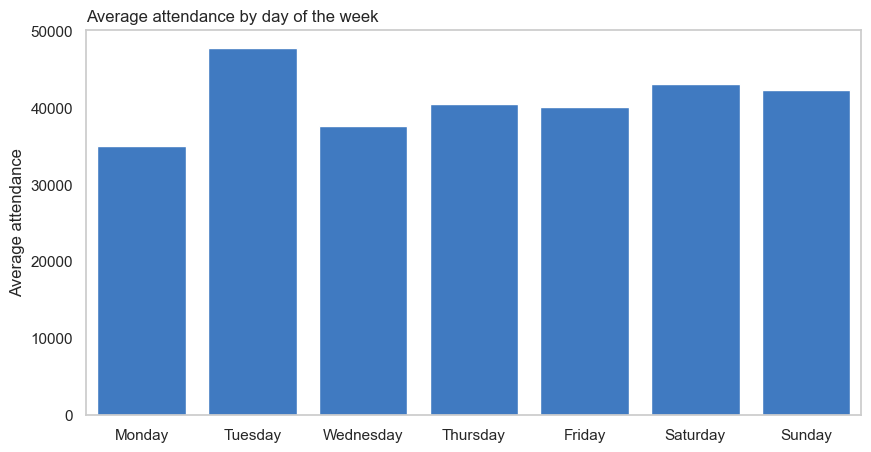

In [5]:
attendance_by_day = df_dodgers.groupby('day_of_week', observed=True)['attend'].agg(['mean', 'count']).round(0)
attendance_by_day.columns = ['average_attendance', 'games']
print(attendance_by_day.sort_values('average_attendance', ascending=False))

plt.figure(figsize=(10, 5))
sns.barplot(x='day_of_week', y='attend', data=df_dodgers, color='#2a78d6', errorbar=None)
plt.title('Average attendance by day of the week', loc='left')
plt.xlabel(''); plt.ylabel('Average attendance')
plt.grid(False)
plt.show()

## 3. Attendance by weather and time of day

           mean  count
skies                 
Clear   41729.0     62
Cloudy  38791.0     19
              mean  count
day_night                
Day        41793.0     15
Night      40869.0     66


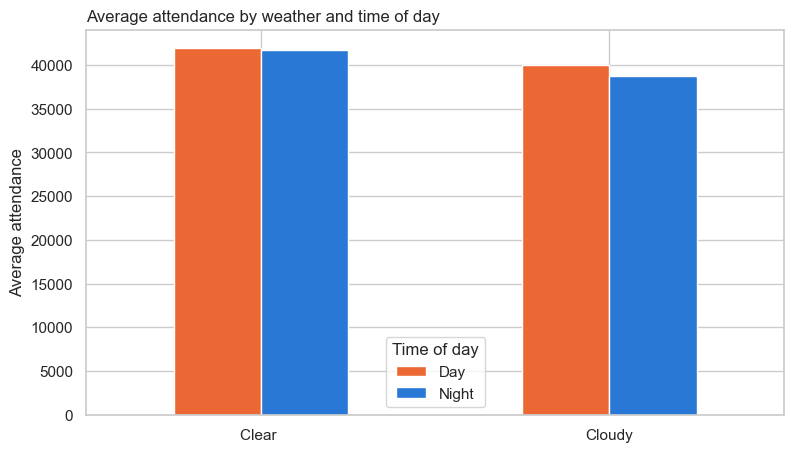

In [6]:
print(df_dodgers.groupby('skies')['attend'].agg(['mean', 'count']).round(0))
print(df_dodgers.groupby('day_night')['attend'].agg(['mean', 'count']).round(0))

attendance_by_weather = df_dodgers.groupby(['skies', 'day_night'])['attend'].mean()
attendance_by_weather.unstack().plot(kind='bar', figsize=(9, 5), color=['#eb6834', '#2a78d6'], rot=0)
plt.title('Average attendance by weather and time of day', loc='left')
plt.xlabel(''); plt.ylabel('Average attendance')
plt.legend(title='Time of day')
plt.show()

## 4. Attendance by promotion
Each promotion's average is for the games where it was offered. The number of games matters: some promotions were only run two or three times.

Average attendance with no promotion: 38,201
 promotion  average_attendance  games
Bobblehead             53145.0     11
     Shirt             46644.0      3
 Fireworks             41078.0     14
       Cap             38190.0      2


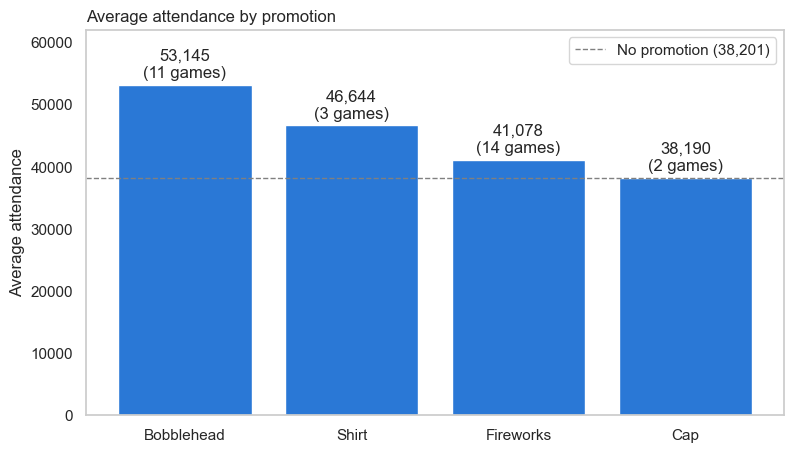

In [7]:
promos = ['bobblehead', 'shirt', 'fireworks', 'cap']
promo_data = pd.DataFrame({
    'promotion': [p.capitalize() for p in promos],
    'average_attendance': [df_dodgers.loc[df_dodgers[p] == 'YES', 'attend'].mean() for p in promos],
    'games': [(df_dodgers[p] == 'YES').sum() for p in promos],
}).sort_values('average_attendance', ascending=False)
no_promo_avg = df_dodgers.loc[(df_dodgers[promos] == 'NO').all(axis=1), 'attend'].mean()
print(f'Average attendance with no promotion: {no_promo_avg:,.0f}')
print(promo_data.round(0).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(promo_data['promotion'], promo_data['average_attendance'], color='#2a78d6')
ax.bar_label(bars, labels=[f"{a:,.0f}\n({g} games)" for a, g in zip(promo_data['average_attendance'], promo_data['games'])], padding=3)
ax.axhline(no_promo_avg, color='grey', linestyle='--', lw=1, label=f'No promotion ({no_promo_avg:,.0f})')
ax.set_ylim(0, 62000); ax.set_ylabel('Average attendance')
ax.set_title('Average attendance by promotion', loc='left')
ax.legend(loc='upper right'); ax.grid(False)
plt.show()

## 5. Is it the promotion or the day?
Promotions are not spread evenly across the week, so a promotion's average can partly reflect the day it ran on. Comparing games on the same day of the week, with and without the promotion, separates the two.

In [8]:
print('Fireworks nights by day of the week:')
print(pd.crosstab(df_dodgers['day_of_week'], df_dodgers['fireworks']).loc[lambda t: t['YES'] > 0])
print()
bobble_by_day = df_dodgers.groupby(['day_of_week', 'bobblehead'], observed=True)['attend'].mean().unstack()
bobble_by_day['lift'] = bobble_by_day['YES'] - bobble_by_day['NO']
print('Bobblehead vs. no bobblehead, same day of the week:')
print(bobble_by_day.dropna().round(0))

Fireworks nights by day of the week:
fireworks    NO  YES
day_of_week         
Wednesday    11    1
Friday        0   13

Bobblehead vs. no bobblehead, same day of the week:
bobblehead        NO      YES     lift
day_of_week                           
Tuesday      43327.0  52892.0   9565.0
Thursday     32803.0  51814.0  19010.0
Saturday     41063.0  54128.0  13065.0
Sunday       41178.0  55359.0  14181.0


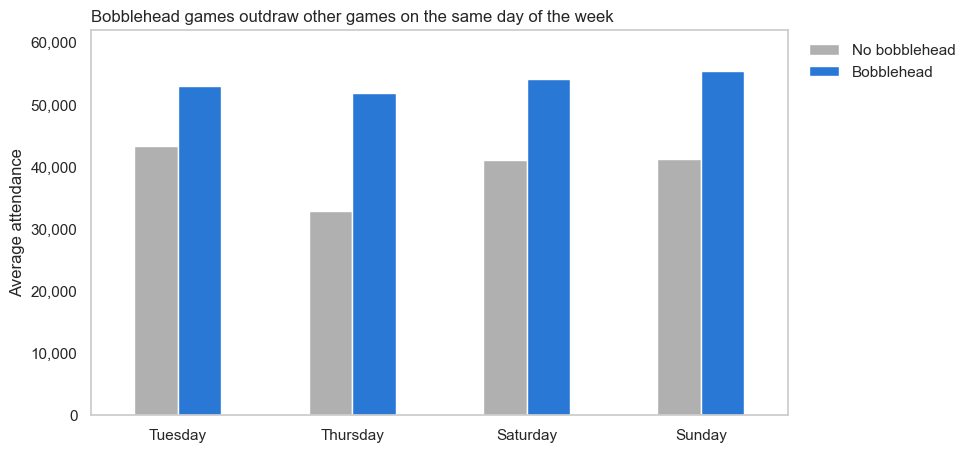

In [9]:
plot_df = bobble_by_day.dropna()[['NO', 'YES']]
ax = plot_df.plot(kind='bar', figsize=(9, 5), color=['#b0b0b0', '#2a78d6'], rot=0)
ax.set_title('Bobblehead games outdraw other games on the same day of the week', loc='left')
ax.set_xlabel(''); ax.set_ylabel('Average attendance')
ax.legend(['No bobblehead', 'Bobblehead'], loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False)
ax.set_ylim(0, 62000)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.grid(False)
plt.show()

## Findings and recommendation
- **Tuesday has the highest average attendance (47,741), and Monday the lowest (34,966).** Part of Tuesday's lead comes from promotions: 6 of the 13 Tuesday games were bobblehead nights. Even without a bobblehead, Tuesday games averaged 43,327, still the highest of any day.
- **Bobbleheads are the one promotion with a clear, repeatable effect.** The 11 bobblehead games averaged 53,145, and the lift shows up on every day it was tried: +9,565 on Tuesday, +19,010 on Thursday, +13,065 on Saturday and +14,181 on Sunday.
- **The other promotions are hard to judge.** Shirt games averaged 46,644 but there were only 3 of them; cap games averaged 38,190 across only 2. Fireworks games averaged 41,078, about the overall average, but 13 of the 14 fireworks nights were Fridays, so their effect cannot be separated from the day itself.
- **Weather and time of day matter less.** Clear-sky games averaged 41,729 vs. 38,791 for cloudy ones, and day games 41,793 vs. 40,869 for night games.
- **Recommendation:** run bobblehead promotions on Mondays, the weakest day, which has never had one. Track Monday attendance with and without the promotion to confirm the lift before rolling it out further.
- **Limitations:** one season of 81 games, and each promotion only ran a handful of times, so these are patterns to test rather than proven causes. Opponent quality and the month of the season, which also affect attendance, were not analyzed here.

**Correction note:** the original version ranked fireworks second among promotions. On average attendance, shirts were second (46,644, from only 3 games) and fireworks third (41,078). The recommendation itself is unchanged and is now backed by a same-day comparison. The original notebook is in `earlier_versions/`.